# AutoML for the E82 Kaggle classification challenge
**Goal:** Automatically search LightGBM, XGBoost, CatBoost, and Extra Trees to maximize **ROC-AUC**, then create a Kaggle submission with columns `id, output`.

Designed for your ~4,584-row / 669-feature data and a 16-GB Apple Silicon Mac. FLAML uses cost-aware hyperparameter optimization. **AutoML is not guaranteed to beat your existing 0.77 leaderboard score.** Compare using the same validation protocol.

Run cells in order; edit `DATA_DIR` and time budgets as necessary.

In [1]:
# Run once in notebook, then restart kernel if needed.
%pip install -q "flaml[automl]" lightgbm xgboost catboost scikit-learn pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from flaml import AutoML
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

SEED = 42
DATA_DIR = Path('.')  # change to Path('.') if files are beside notebook
TRAIN_PATH = DATA_DIR / 'train_data.csv'
TEST_PATH = DATA_DIR / 'test_data.csv'
SAMPLE_PATH = DATA_DIR / 'sample_solution.csv'
VALIDATION_BUDGET_SECONDS = 300  # increase to 600+ for deeper search
FINAL_BUDGET_SECONDS = 600       # increase to 1200+ for deeper search
ESTIMATORS = ['lgbm', 'xgboost', 'catboost', 'extra_tree']

for p in [TRAIN_PATH, TEST_PATH]:
    if not p.exists():
        raise FileNotFoundError(f'Cannot find {p.resolve()}. Update DATA_DIR.')
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
assert 'output' in train.columns, 'Training data must have output target.'
print('Train:', train.shape, 'Test:', test.shape)
print('Target class shares:')
print(train['output'].value_counts(normalize=True))

Train: (4584, 670) Test: (1732, 669)
Target class shares:
output
1    0.844895
0    0.155105
Name: proportion, dtype: float64


## 1. Features and labels
Preserve the original test row order. Exclude `id` (if present) from the predictors; it should only identify rows. FLAML handles missing values and categorical predictors, so we do **not** fit imputation on the full dataset before validation.

In [5]:
TARGET = 'output'
ID_COL = 'id'
feature_cols = [c for c in train.columns if c not in {TARGET, ID_COL}]
missing_in_test = set(feature_cols) - set(test.columns)
if missing_in_test:
    raise ValueError(f'Test file missing training features: {sorted(missing_in_test)[:10]}')
X = train[feature_cols].copy()
y = train[TARGET].astype(int).copy()
X_test = test.reindex(columns=feature_cols).copy()

# Set category dtype consistently between train and test.
for col in feature_cols:
    if pd.api.types.is_object_dtype(X[col]) or pd.api.types.is_string_dtype(X[col]):
        categories = pd.Index(pd.concat([X[col], X_test[col]], ignore_index=True).dropna().unique())
        X[col] = pd.Categorical(X[col], categories=categories)
        X_test[col] = pd.Categorical(X_test[col], categories=categories)

assert set(y.dropna().unique()) == {0, 1}, 'This notebook assumes binary labels 0 and 1.'
print('Predictor count:', len(feature_cols), 'Missing values:', int(X.isna().sum().sum()))
print('Categorical features:', X.select_dtypes(include='category').columns.tolist())

Predictor count: 669 Missing values: 0
Categorical features: ['subject', 'state']


## 2. Holdout check (not used to select models)
A stratified holdout gives an interpretable estimate of generalization. FLAML runs cross-validation **only within the training fold**, avoiding use of the holdout during tuning. For a final stronger result, repeat with other seeds, but do not overfit to the Kaggle leaderboard.

In [6]:
X_fit, X_holdout, y_fit, y_holdout = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
search_settings = dict(
    task='classification',
    metric='roc_auc',  # exactly matches Kaggle ranking metric
    estimator_list=ESTIMATORS,
    eval_method='cv',
    n_splits=3,             # 5 for more robust CV at a higher compute cost
    split_type='stratified',
    time_budget=VALIDATION_BUDGET_SECONDS,
    n_jobs=2,               # conservative for M2 / 16 GB
    seed=SEED,
    verbose=1,
    log_file_name='flaml_validation.log',
)
automl_val = AutoML()
automl_val.fit(X_train=X_fit, y_train=y_fit, **search_settings)
print('Best algorithm:', automl_val.best_estimator)
print('Best config:', automl_val.best_config)
print('Internal CV ROC-AUC:', round(1 - automl_val.best_loss, 5))

Best algorithm: extra_tree
Best config: {'n_estimators': 541, 'max_features': np.float64(0.8724140759974085), 'max_leaves': 229, 'criterion': np.str_('entropy')}
Internal CV ROC-AUC: 0.85968


Untouched holdout ROC-AUC: 0.89893


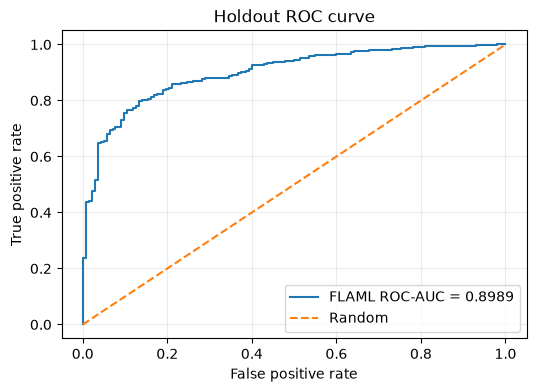

In [7]:
holdout_probs = automl_val.predict_proba(X_holdout)[:, 1]
holdout_auc = roc_auc_score(y_holdout, holdout_probs)
print(f'Untouched holdout ROC-AUC: {holdout_auc:.5f}')
fpr, tpr, _ = roc_curve(y_holdout, holdout_probs)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'FLAML ROC-AUC = {holdout_auc:.4f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Holdout ROC curve'); plt.legend(); plt.grid(alpha=0.25)
plt.show()

## 3. Final AutoML search using all labeled rows
Once the holdout result looks reasonable, search using **all** training data with CV and retain the final FLAML model. This is a fresh search, not a reuse of the holdout model.

In [8]:
final_settings = {**search_settings,
                  'time_budget': FINAL_BUDGET_SECONDS,
                  'n_splits': 5,
                  'log_file_name': 'flaml_full_training.log'}
automl_final = AutoML()
automl_final.fit(X_train=X, y_train=y, **final_settings)
print('Final best algorithm:', automl_final.best_estimator)
print('Final best parameters:', automl_final.best_config)
print('Final internal CV ROC-AUC:', round(1 - automl_final.best_loss, 5))

Final best algorithm: lgbm
Final best parameters: {'n_estimators': 1794, 'num_leaves': 17, 'min_child_samples': 5, 'learning_rate': np.float64(0.1629082709189104), 'log_max_bin': 5, 'colsample_bytree': 1.0, 'reg_alpha': np.float64(0.00369615732233805), 'reg_lambda': np.float64(10.28761864393158)}
Final internal CV ROC-AUC: 0.85321


## 4. Predict class-1 probabilities and submit
ROC-AUC uses probabilities/ranking, **not 0/1 predictions**. The output format below aligns with `sample_solution.csv` when available, otherwise uses the test file's ID column (or the test index, as in your earlier notebooks).

In [9]:
test_probs = automl_final.predict_proba(X_test)[:, 1]
assert len(test_probs) == len(test) and np.isfinite(test_probs).all()

if SAMPLE_PATH.exists():
    submission = pd.read_csv(SAMPLE_PATH)
    if list(submission.columns) != ['id', 'output']:
        raise ValueError(f'Unexpected sample solution columns: {submission.columns.tolist()}')
    if len(submission) != len(test):
        raise ValueError('Sample solution and test row counts differ.')
    if ID_COL in test.columns and not np.array_equal(submission['id'], test[ID_COL]):
        raise ValueError('Sample solution IDs do not match test IDs in order.')
else:
    ids = test[ID_COL].values if ID_COL in test.columns else test.index.to_numpy()
    submission = pd.DataFrame({'id': ids, 'output': np.nan})

submission['output'] = test_probs
submission.to_csv('automl_flaml_submission.csv', index=False)
print(submission.head())
print('Saved: automl_flaml_submission.csv; shape:', submission.shape)
print('Probability range:', submission['output'].min(), submission['output'].max())

   id    output
0   0  0.965467
1   1  0.999243
2   2  0.995416
3   3  0.984980
4   4  0.932875
Saved: automl_flaml_submission.csv; shape: (1732, 2)
Probability range: 0.0009280643327782661 0.9999998517987525


## 5. Optional: Kaggle upload
The submission CSV is ready. To upload from Jupyter with the CLI, first authenticate Kaggle and replace the competition slug; **do not execute this cell until you have done so**.

```python
# %pip install -q kaggle
# !kaggle competitions submit -c YOUR_COMPETITION_SLUG -f automl_flaml_submission.csv -m "FLAML AutoML ROC-AUC"
```

**Next experiment:** evaluate your 0.77-scoring ET hybrid and the FLAML model on the **same** holdout, and blend their probabilities only if holdout ROC-AUC improves. Avoid selecting a blend solely because of public Kaggle leaderboard changes.

FLAML documentation: https://microsoft.github.io/FLAML/docs/Examples/AutoML-Classification/